# Comparing HMM emission models on S&P 500 returns

Fit several emission distributions to the **same ten years of daily S&P 500 log returns** and look at what each one learns. No trading strategy appears here. The question is descriptive: *how does the emission change the regimes the HMM finds?*

- **Data:** the repo's existing S&P 500 price index, daily log return $r_t=\log P_t-\log P_{t-1}$, one feature.
- **Hidden states:** $K=3$ for every candidate, so the Markov chain is the same size and only the emission changes.
- **Candidates:** a single **Gaussian**, a **Gaussian mixture** with 2 or 3 components per state (these capture within-state shape, not extra regimes), and a **Student-t** (heavy tails with one degrees-of-freedom parameter per state). The package has no Student-t emission, so [`compare_emission_models.py`](compare_emission_models.py) adds one.
- **Fitting:** Baum-Welch from the package, several deterministic restarts, best training log likelihood kept.

**Reading the results.** Everything below is fitted and evaluated on the same ten years, so likelihoods favor flexible models by construction; AIC and BIC penalize that but are only rough guides for HMMs. State labels are arbitrary, so states are ordered by fitted volatility and called low, mid, and high. Regime paths use **smoothed** probabilities that look at the whole sequence, which suits description but not forecasting. There is no ground truth here, so a different partition is not automatically a better or worse one.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import adjusted_rand_score

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/flexible_emission_hmm").exists())
sys.path.insert(0, str(root / "src"))
sys.path.insert(0, str(root / "notebooks/sp500/diagnostic"))

import compare_emission_models as ce
from flexible_emission_hmm.feature import daily_log_return

START_YEAR, END_YEAR = 2000, 2009
N_STATES, N_STARTS, MAX_ITER = 3, 8, 1000
CANDIDATES = {"Gaussian": 1, "GMM (2 comp.)": 2, "GMM (3 comp.)": 3, "Student-t": 1}
RANK_NAMES = ["low-vol", "mid-vol", "high-vol"]
COLORS = {"Gaussian": "#4477AA", "GMM (2 comp.)": "#CC7722", "GMM (3 comp.)": "#228833", "Student-t": "#AA3377"}
STATE_COLORS = ["#2a9d8f", "#e9c46a", "#d62828"]

prices = pd.read_csv(root / "data/processed/sp500_index_price.csv", parse_dates=["YYYYMMDD"]).set_index("YYYYMMDD")["DlyPrcInd"].sort_index()
returns = daily_log_return(prices).dropna().loc[str(START_YEAR):str(END_YEAR)]
X = returns.to_numpy()[:, None]
extreme = returns.abs() >= returns.abs().quantile(0.99)
print(f"{returns.index[0].date()} to {returns.index[-1].date()}: {len(returns):,} daily returns")
print(f"mean {100*returns.mean():.3f}%  sd {100*returns.std():.3f}%  min {100*returns.min():.2f}%  max {100*returns.max():.2f}%")
print(f"excess kurtosis {returns.kurt():.2f}; 'extreme days' = largest 1% of |r| ({extreme.sum()} days, |r| >= {100*returns.abs().quantile(0.99):.2f}%)")

2000-01-03 to 2009-12-31: 2,515 daily returns
mean -0.011%  sd 1.401%  min -9.47%  max 10.96%
excess kurtosis 7.66; 'extreme days' = largest 1% of |r| (26 days, |r| >= 4.99%)


## 1. Fit every candidate

Each candidate gets the same observations and the same number of restarts. The Student-t also tries one start copied from the best Gaussian fit, because it contains the Gaussian as a limit and random starts can miss that region. Free-parameter counts: $(K-1)+K(K-1)$ for the start and transition probabilities, plus $2K$ for Gaussian, $K(3M-1)$ for an $M$-component mixture, and $3K$ for Student-t.

In [2]:
fits, attempts = ce.fit_candidates(X, CANDIDATES, n_states=N_STATES, n_starts=N_STARTS, max_iter=MAX_ITER)
models = {name: fit["model"] for name, fit in fits.items()}
summary = pd.DataFrame({
    name: {"log likelihood": f["log_likelihood"], "free parameters": f["n_parameters"], "AIC": f["aic"], "BIC": f["bic"],
           "selected start": f["start"]}
    for name, f in fits.items()
}).T
for column in ["log likelihood", "AIC", "BIC"]:
    summary[column] = summary[column].astype(float).round(1)
display(summary)
print("Lower AIC/BIC is better; each is a rough guide for HMMs and is computed in-sample.")

Lower AIC/BIC is better; each is a rough guide for HMMs and is computed in-sample.


,log likelihood,free parameters,AIC,BIC,selected start
Gaussian,7782.8,14,-15537.7,-15456.1,seed 5
GMM (2 comp.),7807.0,23,-15567.9,-15433.8,seed 2
GMM (3 comp.),7810.0,32,-15555.9,-15369.3,seed 4
Student-t,7783.8,17,-15533.6,-15434.5,Gaussian fit


### Fit reliability

Random restarts can land in different local optima, and EM can stop at the iteration cap before converging. This table lists every attempt so a model difference is not mistaken for an optimizer difference.

In [3]:
reliability = attempts.groupby("model", sort=False).agg(
    attempts=("start", "size"), converged=("converged", "sum"),
    best_loglik=("log_likelihood", "max"), worst_loglik=("log_likelihood", "min"),
    median_iterations=("iterations", "median"), total_seconds=("seconds", "sum"),
).round(2)
display(reliability)
spread = (reliability["best_loglik"] - reliability["worst_loglik"]).round(1)
print("Restart spread in log likelihood (best - worst):", spread.to_dict())
display(attempts.pivot_table(index="start", columns="model", values="log_likelihood", sort=False).round(1)[list(CANDIDATES)])

Restart spread in log likelihood (best - worst): {'Gaussian': 101.1, 'GMM (2 comp.)': 81.7, 'GMM (3 comp.)': 76.9, 'Student-t': 63.7}


,attempts,converged,best_loglik,worst_loglik,median_iterations,total_seconds
model,,,,,,
Gaussian,8,8,7782.85,7681.71,319.5,43.92
GMM (2 comp.),8,8,7806.95,7725.25,526.0,83.24
GMM (3 comp.),8,8,7809.96,7733.08,521.5,104.53
Student-t,9,9,7783.82,7720.12,504.0,101.38


model,Gaussian,GMM (2 comp.),GMM (3 comp.),Student-t
start,,,,
seed 0,7681.7,7730.6,7733.1,7725.4
seed 1,7681.7,7730.7,7734.9,7725.4
seed 2,7681.7,7807.0,7734.9,7725.4
seed 3,7782.8,7730.5,7734.8,7720.1
seed 4,7681.7,7725.3,7810.0,7725.4
seed 5,7782.8,7806.5,7734.4,7720.1
seed 6,7681.7,7805.5,7734.6,7720.1
seed 7,7782.8,7807.0,7808.8,7725.2
Gaussian fit,NaN,NaN,NaN,7783.8


## 2. What distribution does each model assign to returns?

The stationary mixture of each model's state densities, against the observed returns. The left panel is the center; the right is the same fit on a **log scale** so the tails are visible. Differences in the tails are where the emissions disagree most.

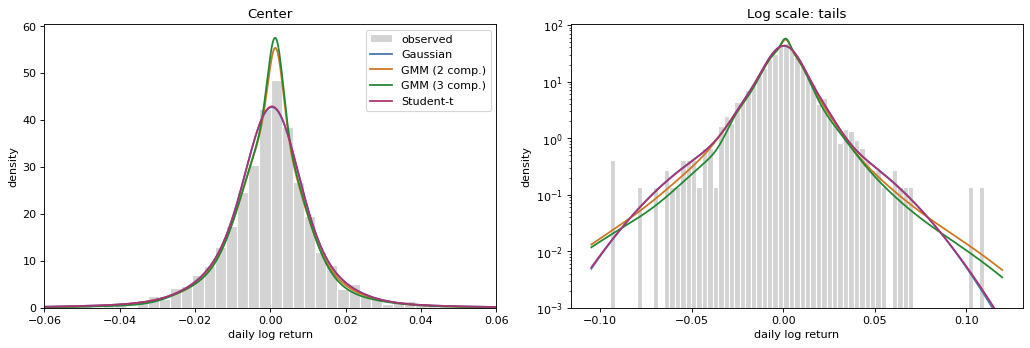

,P(r <= -3%),P(r >= +3%),implied overall sd (%)
Gaussian,0.0224,0.0186,1.3664
GMM (2 comp.),0.0202,0.0164,1.3070
GMM (3 comp.),0.0149,0.0149,1.2323
Student-t,0.0224,0.0185,1.3636
observed,0.0219,0.0211,1.4006


In [4]:
grid = np.linspace(returns.min() - 0.01, returns.max() + 0.01, 1500)
density = {name: ce.marginal_density(model, grid) for name, model in models.items()}
bins = np.linspace(returns.min(), returns.max(), 70)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, log_scale in zip(axes, (False, True)):
    ax.hist(returns, bins=bins, density=True, color="lightgray", edgecolor="white", label="observed")
    for name, d in density.items():
        ax.plot(grid, d, color=COLORS[name], lw=1.6, label=name)
    ax.set(xlabel="daily log return", ylabel="density")
    if log_scale:
        ax.set(yscale="log", ylim=(1e-3, None), title="Log scale: tails")
    else:
        ax.set(xlim=(-0.06, 0.06), title="Center")
axes[0].legend()
fig.tight_layout()
plt.show()

_integrate = getattr(np, "trapezoid", None) or np.trapz
tail_rows = {}
for name, d in density.items():
    tail_rows[name] = {
        "P(r <= -3%)": float(_integrate(d[grid <= -0.03], grid[grid <= -0.03])),
        "P(r >= +3%)": float(_integrate(d[grid >= 0.03], grid[grid >= 0.03])),
        "implied overall sd (%)": 100 * float(np.sqrt(_integrate(d * grid**2, grid) - _integrate(d * grid, grid) ** 2)),
    }
tail_rows["observed"] = {"P(r <= -3%)": float((returns <= -0.03).mean()), "P(r >= +3%)": float((returns >= 0.03).mean()),
                         "implied overall sd (%)": 100 * returns.std()}
display(pd.DataFrame(tail_rows).T.round(4))

## 3. The learned states

For each model the states are ordered by fitted standard deviation. Mixtures are collapsed to their overall state mean and standard deviation. **Stationary share** is the long-run fraction of time the fitted chain spends in the state; **expected duration** is $1/(1-a_{kk})$ days from the self-transition probability $a_{kk}$. For the Student-t, `dof` is the state's degrees of freedom: small values mean heavy tails (variance exists only above 2), and large values approach a Gaussian.

In [5]:
order = {name: ce.volatility_order(model) for name, model in models.items()}
state_tables = {}
for name, model in models.items():
    idx = order[name]
    info = ce.state_summary(model)
    transitions = model.states.transitions
    table = pd.DataFrame({
        "mean (%/day)": 100 * info["mean"][idx], "sd (%/day)": 100 * info["sd"][idx],
        "stationary share": ce.stationary_distribution(transitions)[idx],
        "self-transition": np.diag(transitions)[idx],
        "expected duration (days)": 1 / (1 - np.diag(transitions)[idx]),
    }, index=RANK_NAMES)
    if "largest_component_weight" in info:
        table["largest component weight"] = info["largest_component_weight"][idx]
    if "dof" in info:
        table["dof"] = info["dof"][idx]
    state_tables[name] = table
    print(f"\n{name}")
    display(table.round(3))


Gaussian

GMM (2 comp.)

GMM (3 comp.)

Student-t


,mean (%/day),sd (%/day),stationary share,self-transition,expected duration (days)
low-vol,0.050,0.655,0.449,0.994,158.113
mid-vol,-0.020,1.276,0.451,0.987,76.453
high-vol,-0.213,3.072,0.100,0.969,32.508


,mean (%/day),sd (%/day),stationary share,self-transition,expected duration (days),largest component weight
low-vol,0.047,0.670,0.488,0.998,419.936,0.829
mid-vol,-0.014,1.263,0.415,0.992,121.657,0.798
high-vol,-0.207,2.993,0.097,0.977,43.200,0.809


,mean (%/day),sd (%/day),stationary share,self-transition,expected duration (days),largest component weight
low-vol,0.045,0.678,0.54,0.999,705.995,0.571
mid-vol,-0.005,1.252,0.38,0.992,131.802,0.625
high-vol,-0.234,2.976,0.08,0.974,37.811,0.464


,mean (%/day),sd (%/day),stationary share,self-transition,expected duration (days),dof
low-vol,0.051,0.656,0.451,0.994,162.801,199.564
mid-vol,-0.020,1.278,0.450,0.987,78.786,199.527
high-vol,-0.216,3.066,0.099,0.970,33.648,198.424


### Transition matrices

Rows are the current state and columns the next state, in volatility order. Large diagonals mean persistent regimes. Off-diagonal mass shows how the model moves between regimes, for example whether the high-vol state is entered directly from the low-vol state.

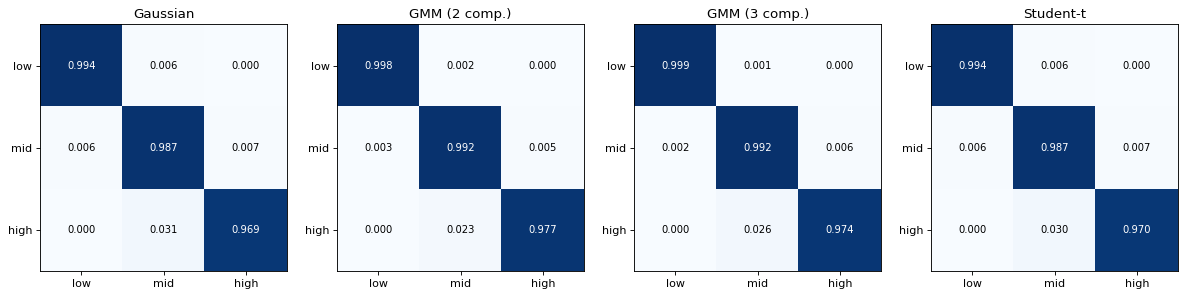

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, model) in zip(axes, models.items()):
    idx = order[name]
    matrix = model.states.transitions[np.ix_(idx, idx)]
    ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    for i in range(N_STATES):
        for j in range(N_STATES):
            ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", color="white" if matrix[i, j] > 0.5 else "black", fontsize=9)
    ax.set(title=name, xticks=range(3), yticks=range(3), xticklabels=["low", "mid", "high"], yticklabels=["low", "mid", "high"])
fig.tight_layout()
plt.show()

### State-conditional densities

Each panel shows the density of every state in one model, on a log scale. This is where the emission choice changes the *role* of a state. A Gaussian state is a single parabola on this plot. A heavy-tailed or mixture state has fat shoulders, so a calm state can still absorb occasional large moves instead of handing them to a separate high-volatility state.

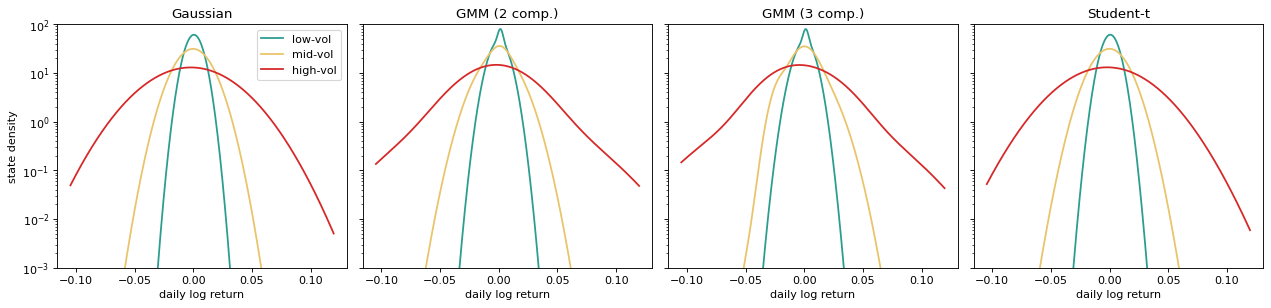

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    log_p = model.emission.log_prob(grid[:, None])
    for rank, k in enumerate(order[name]):
        ax.plot(grid, np.exp(log_p[:, k]), color=STATE_COLORS[rank], lw=1.6, label=RANK_NAMES[rank])
    ax.set(yscale="log", ylim=(1e-3, 1e2), title=name, xlabel="daily log return")
axes[0].set_ylabel("state density")
axes[0].legend()
fig.tight_layout()
plt.show()

## 4. The inferred regime paths

For every model: smoothed state probabilities $P(S_t=k\mid r_{1:T})$, with each day assigned to its most probable state. These use the whole ten-year sequence, so they describe the past and are not available in real time.

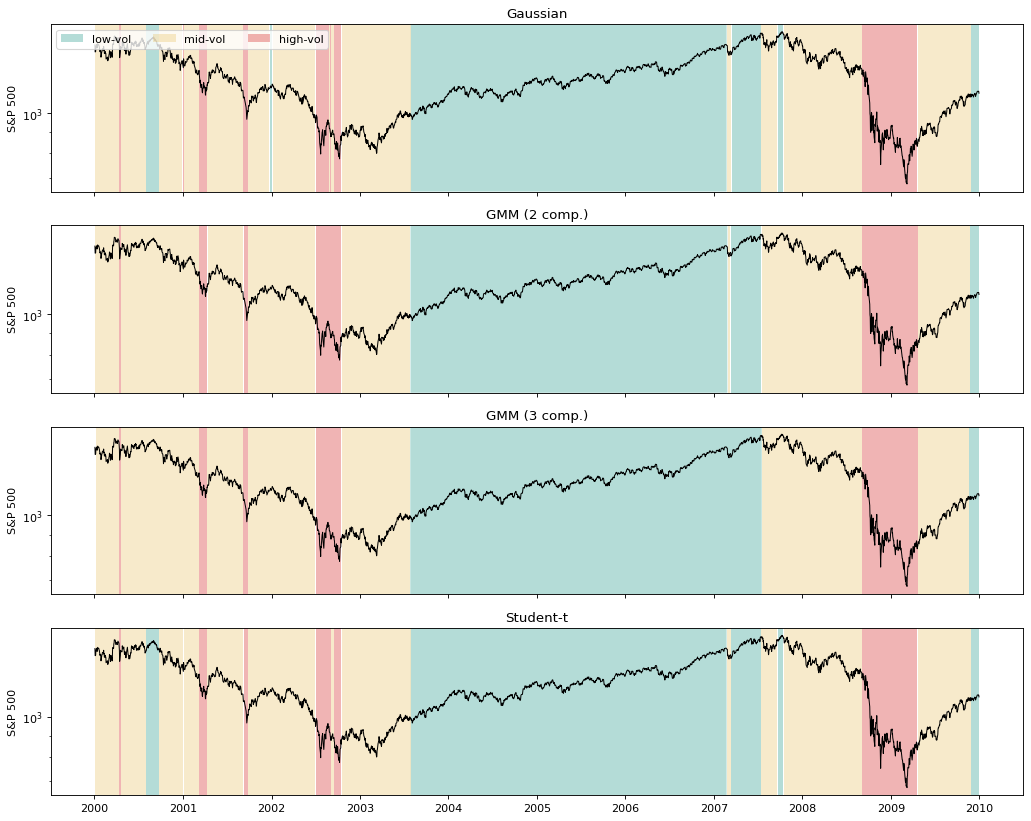

In [8]:
posterior = {name: model.predict_proba(X)[:, order[name]] for name, model in models.items()}
path = {name: pd.Series(p.argmax(axis=1), index=returns.index, name=name) for name, p in posterior.items()}
price = prices.loc[returns.index[0]:returns.index[-1]]

fig, axes = plt.subplots(len(models), 1, figsize=(13, 2.6 * len(models)), sharex=True)
for ax, (name, states) in zip(axes, path.items()):
    ax.semilogy(price.index, price, color="black", lw=0.9)
    for rank in range(N_STATES):
        ax.fill_between(states.index, 0, 1, where=(states == rank).to_numpy(), transform=ax.get_xaxis_transform(),
                        color=STATE_COLORS[rank], alpha=0.35, linewidth=0, label=RANK_NAMES[rank])
    ax.set(ylabel="S&P 500", title=name)
axes[0].legend(ncol=3, loc="upper left")
fig.tight_layout()
plt.show()

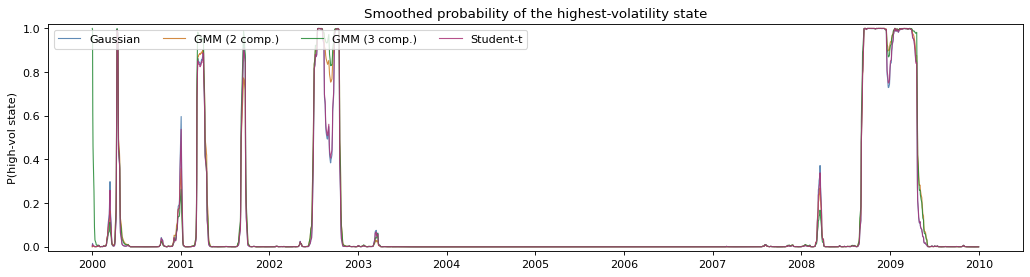

In [9]:
fig, ax = plt.subplots(figsize=(13, 3.6))
for name, p in posterior.items():
    ax.plot(returns.index, p[:, 2], color=COLORS[name], lw=1.0, alpha=0.85, label=name)
ax.set(ylabel="P(high-vol state)", title="Smoothed probability of the highest-volatility state", ylim=(-0.02, 1.02))
ax.legend(ncol=4, loc="upper left")
fig.tight_layout()
plt.show()

### Occupancy and persistence of the inferred paths

Share of days each model assigns to each state, and the spells (unbroken runs in one state). Many short spells suggest a state that fires on isolated days; few long spells suggest a persistent regime.

In [10]:
def spells(states):
    runs = (states != states.shift()).cumsum()
    return states.groupby(runs).agg(["first", "size"]).rename(columns={"first": "state", "size": "length"})

rows = []
for name, states in path.items():
    runs = spells(states)
    for rank in range(N_STATES):
        lengths = runs.loc[runs.state == rank, "length"]
        rows.append({"model": name, "state": RANK_NAMES[rank], "share of days": float((states == rank).mean()),
                     "spells": len(lengths), "median spell (days)": float(lengths.median()) if len(lengths) else np.nan,
                     "longest spell (days)": int(lengths.max()) if len(lengths) else 0,
                     "spells <= 3 days": int((lengths <= 3).sum())})
display(pd.DataFrame(rows).set_index(["model", "state"]).round(3))

yearly = pd.DataFrame({name: (states == 2).groupby(states.index.year).mean() for name, states in path.items()})
print("Share of each year spent in the high-vol state:")
display(yearly.round(2))

Share of each year spent in the high-vol state:


share of days  ...  spells <= 3 days
model         state                    ...                  
Gaussian      low-vol           0.425  ...                 0
              mid-vol           0.472  ...                 1
              high-vol          0.103  ...                 2
GMM (2 comp.) low-vol           0.404  ...                 0
              mid-vol           0.488  ...                 0
              high-vol          0.108  ...                 0
GMM (3 comp.) low-vol           0.409  ...                 0
              mid-vol           0.481  ...                 0
              high-vol          0.110  ...                 1
Student-t     low-vol           0.422  ...                 0
              mid-vol           0.474  ...                 0
              high-vol          0.104  ...                 1

[12 rows x 5 columns]

,Gaussian,GMM (2 comp.),GMM (3 comp.),Student-t
YYYYMMDD,,,,
2000,0.02,0.02,0.04,0.02
2001,0.13,0.12,0.13,0.12
2002,0.25,0.30,0.30,0.27
2003,0.00,0.00,0.00,0.00
2004,0.00,0.00,0.00,0.00
2005,0.00,0.00,0.00,0.00
2006,0.00,0.00,0.00,0.00
2007,0.00,0.00,0.00,0.00
2008,0.32,0.32,0.33,0.32


## 5. How the models disagree

Because state labels are arbitrary, the comparison uses volatility rank. The adjusted Rand index (ARI) measures whether two models group the same days together regardless of label names: 1 means identical partitions and values near 0 mean chance-level agreement. The cross-tabulations show *how* two models differ, for instance whether the Gaussian's high-vol days are split between a mid and a high state by another model.

In [11]:
names = list(models)
ari = pd.DataFrame(1.0, index=names, columns=names)
for a in names:
    for b in names:
        ari.loc[a, b] = adjusted_rand_score(path[a], path[b])
print("Adjusted Rand index between inferred state paths:")
display(ari.round(3))

def crosstab(a, b):
    table = pd.crosstab(path[a].map(dict(enumerate(RANK_NAMES))), path[b].map(dict(enumerate(RANK_NAMES))))
    return table.reindex(index=RANK_NAMES, columns=RANK_NAMES, fill_value=0)

for other in names[1:]:
    print(f"\nRows: Gaussian state, columns: {other} state (days)")
    display(crosstab("Gaussian", other))

Adjusted Rand index between inferred state paths:

Rows: Gaussian state, columns: GMM (2 comp.) state (days)

Rows: Gaussian state, columns: GMM (3 comp.) state (days)

Rows: Gaussian state, columns: Student-t state (days)


,Gaussian,GMM (2 comp.),GMM (3 comp.),Student-t
Gaussian,1.000,0.881,0.861,0.981
GMM (2 comp.),0.881,1.000,0.974,0.899
GMM (3 comp.),0.861,0.974,1.000,0.877
Student-t,0.981,0.899,0.877,1.000


GMM (2 comp.),low-vol,mid-vol,high-vol
Gaussian,,,
low-vol,1006,62,0
mid-vol,10,1163,15
high-vol,0,3,256


GMM (3 comp.),low-vol,mid-vol,high-vol
Gaussian,,,
low-vol,1006,62,0
mid-vol,23,1146,19
high-vol,0,2,257


Student-t,low-vol,mid-vol,high-vol
Gaussian,,,
low-vol,1060,8,0
mid-vol,1,1183,4
high-vol,0,2,257


## 6. Where do the extreme days go?

The 1% of days with the largest $|r_t|$. For each model: which state those days are assigned to, and how much of the high-vol state is made of them. If a model sends most extremes to a small, short-lived state, that state may be describing outliers rather than a regime. If it keeps extremes inside broader states, the high-vol state is more likely a sustained condition. Neither is automatically right; this shows what each emission is doing.

days  ...  state sd of realized r (%)
model         state           ...                            
Gaussian      low-vol   1068  ...                       0.664
              mid-vol   1188  ...                       1.275
              high-vol   259  ...                       3.121
GMM (2 comp.) low-vol   1016  ...                       0.668
              mid-vol   1228  ...                       1.263
              high-vol   271  ...                       3.044
GMM (3 comp.) low-vol   1029  ...                       0.678
              mid-vol   1210  ...                       1.256
              high-vol   276  ...                       3.032
Student-t     low-vol   1061  ...                       0.664
              mid-vol   1193  ...                       1.274
              high-vol   261  ...                       3.108

[12 rows x 5 columns]

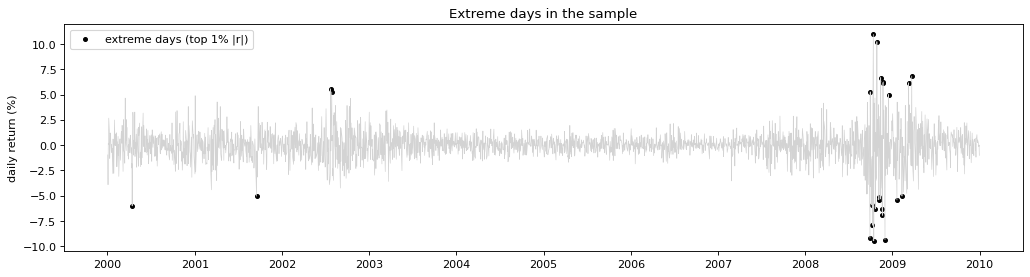

In [12]:
rows = []
for name, states in path.items():
    for rank in range(N_STATES):
        in_state = states == rank
        rows.append({
            "model": name, "state": RANK_NAMES[rank],
            "days": int(in_state.sum()),
            "extreme days in state": int((in_state & extreme).sum()),
            "share of all extreme days": float((in_state & extreme).sum() / extreme.sum()),
            "extreme share of state's days": float((in_state & extreme).sum() / max(in_state.sum(), 1)),
            "state sd of realized r (%)": 100 * float(returns[in_state].std()) if in_state.sum() > 1 else np.nan,
        })
display(pd.DataFrame(rows).set_index(["model", "state"]).round(3))

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(returns.index, 100 * returns, color="lightgray", lw=0.6)
ax.scatter(returns.index[extreme], 100 * returns[extreme], c="black", s=12, label="extreme days (top 1% |r|)")
ax.set(ylabel="daily return (%)", title="Extreme days in the sample")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Realized volatility inside each inferred state

A sanity check that does not use the model's own variance estimate: the sample standard deviation of the actual returns on the days assigned to each state, next to the volatility the model says the state has. The two should be close for a coherent volatility regime. Large gaps mean the state is defined by something other than return scale, such as mean or tail shape.

In [13]:
rows = []
for name, states in path.items():
    fitted_sd = 100 * ce.state_summary(models[name])["sd"][order[name]]
    for rank in range(N_STATES):
        sel = returns[states == rank]
        rows.append({"model": name, "state": RANK_NAMES[rank], "model sd (%)": fitted_sd[rank],
                     "realized sd (%)": 100 * float(sel.std()), "realized mean (%)": 100 * float(sel.mean()),
                     "worst day (%)": 100 * float(sel.min()), "5th percentile (%)": 100 * float(sel.quantile(0.05)), "days": len(sel)})
display(pd.DataFrame(rows).set_index(["model", "state"]).round(3))

model sd (%)  realized sd (%)  ...  5th percentile (%)  days
model         state                                    ...                          
Gaussian      low-vol          0.655            0.664  ...              -1.063  1068
              mid-vol          1.276            1.275  ...              -2.125  1188
              high-vol         3.072            3.121  ...              -5.058   259
GMM (2 comp.) low-vol          0.670            0.668  ...              -1.080  1016
              mid-vol          1.263            1.263  ...              -2.114  1228
              high-vol         2.993            3.044  ...              -5.042   271
GMM (3 comp.) low-vol          0.678            0.678  ...              -1.096  1029
              mid-vol          1.252            1.256  ...              -2.098  1210
              high-vol         2.976            3.032  ...              -5.039   276
Student-t     low-vol          0.656            0.664  ...              -1.060  1061
              mid-vol          1.278            1.274  ...              -2.141  1193
              high-vol         3.066            3.108  ...              -5.047   261

[12 rows x 6 columns]

## 8. What this comparison does and does not show

- **Descriptive only.** One ten-year sample, one asset, no hold-out. Likelihood gains from flexible emissions are in-sample.
- **Smoothed paths use the whole sequence.** They explain history but are not signals.
- **No ground truth.** Differences in the partitions say the emissions disagree, not which is closer to a true regime structure. Judging that would need out-of-sample prediction or independent regime definitions.
- **Local optima.** The reliability table lists every restart. Several seeds stop at clearly worse solutions for every candidate, so the best-of-restarts rule matters, and a different seed budget could change which model looks best.
- **Mixture components are not regimes.** A 3-component state can hold a narrow center and a rare broad tail component within one regime; the state count stays at 3.
- **Ten years is a choice for now.** `START_YEAR` and `END_YEAR` in the setup cell change the sample; 2000-2009 includes the dot-com unwinding and the 2008 crisis.